# Data analysis: features vs label

Exploratory analysis of the ML dataset built by `scripts/07_ml_dataset.py` (full primary cohort, nf-core mode:
460 samples, 199 Stage I lung cancers and 261 non-cancer controls). The goal is to understand the data before
modelling: who is in the cohort, how clean the features are, which technical variables could act as confounders,
and how each feature set relates to the label. Modelling and evaluation are in `scripts/08_ml_analysis.py`.

| file in `notebooks/data/nfcore_full/` | content |
|---|---|
| `X_methylation.tsv` | sample × region methylation fraction (step 04), low-depth values = NaN |
| `X_coverage.tsv` | methylation calls per sample × region |
| `X_<feature>.tsv` | read-level features of step 05 (`meth`, `frac_meth`, `mhl`, `pdr`, `entropy`, ...) |
| `X_sample.tsv` | sample-level fragment-length features |
| `samples.tsv` | label, clinical and technical covariates |
| `regions.tsv` | all 2,473 panel regions with QC stats and the kept / dropped flag |

All statistics here are descriptive and use all samples. They do not feed into any modelling choice.

In [1]:
from itertools import combinations
from math import comb
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 42
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
DATA_DIR = ROOT / "notebooks/data/nfcore_full"
FEATURES_DIR = ROOT / "features/nfcore"
OUT_DIR = ROOT / "results/data_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}          # control, cancer
CLASS_NAMES = {0: "Control", 1: "Stage I cancer"}
BATCH_COLORS = ["#1baf7a", "#8a5cc2"]
MUTED = "#8a8985"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

info = json.loads((DATA_DIR / "dataset_info.json").read_text())
samples = pd.read_csv(DATA_DIR / "samples.tsv", sep="\t").set_index("sample_id")
regions = pd.read_csv(DATA_DIR / "regions.tsv", sep="\t").set_index("region_id")
y = samples["ml_label"].astype(int)
batch = samples["submission_series"]

SETS = {"methylation": pd.read_csv(DATA_DIR / "X_methylation.tsv", sep="\t", index_col="sample_id")}
for name in info["read_feature_sets"]:
    SETS[name] = pd.read_csv(DATA_DIR / f"X_{name}.tsv", sep="\t", index_col="sample_id")
X_sample = pd.read_csv(DATA_DIR / "X_sample.tsv", sep="\t", index_col="sample_id")
coverage = pd.read_csv(DATA_DIR / "X_coverage.tsv", sep="\t", index_col="sample_id")
X = SETS["methylation"]

# A silent row mismatch would invalidate every result below
for M in [*SETS.values(), X_sample, coverage]:
    assert M.index.equals(y.index)
assert X.columns.isin(regions.index[regions["kept"]]).all()

print(f"Samples: {len(y)}  (" + ", ".join(f"{CLASS_NAMES[k]} {v}" for k, v in y.value_counts().sort_index().items()) + ")")
print("Feature sets:", ", ".join(f"{k} ({v.shape[1]})" for k, v in SETS.items()), f"| X_sample ({X_sample.shape[1]})")

Samples: 460  (Control 261, Stage I cancer 199)
Feature sets: methylation (2456), meth (2455), frac_meth (2232), frac_meth_short (208), mhl (2252), pdr (2141), entropy (2141), frac_short (2445) | X_sample (3)


## 1. Cohort and covariates

The two sequencing submissions (`submission_series`) are the main suspect for confounding: they were sequenced
at different times and have different cancer shares. The study's own split (`model_group`: TV for
training/validation, SBT for the single-blind test) is shown as well, because it decides what a model can learn
from each batch.

In [2]:
for col in ["submission_series", "model_group", "stage", "gender"]:
    print(pd.crosstab(samples[col], y.map(CLASS_NAMES), margins=True), "\n")
print(pd.crosstab([samples["model_group"], batch], y.map(CLASS_NAMES)))

ml_label           Control  Stage I cancer  All
submission_series                              
SRR151                  80              28  108
SRR998                 181             171  352
All                    261             199  460 

ml_label     Control  Stage I cancer  All
model_group                              
SBT              137             109  246
TV               124              90  214
All              261             199  460 

ml_label  Control  Stage I cancer  All
stage                                 
Benign         15               0   15
Healthy       246               0  246
IA              0             157  157
IB              0              42   42
All           261             199  460 

ml_label  Control  Stage I cancer  All
gender                                
F             117             115  232
M             144              84  228
All           261             199  460 

ml_label                       Control  Stage I cancer
model_group submiss

In [3]:
numeric = ["age", "dna_input_ng", "median_region_depth", "n_fragments", "mean_region_methylation", "r2_end_ch_meth"]
rows = []
for col in numeric:
    v = samples[col].astype(float)
    a, b = v[y == 0].dropna(), v[y == 1].dropna()
    auc = roc_auc_score(y[v.notna()], v.dropna())
    rows.append({"variable": col, "control_median": a.median(), "cancer_median": b.median(),
                 "auc_vs_label": auc, "p_value": stats.mannwhitneyu(a, b).pvalue, "test": "Mann-Whitney"})
for col in ["submission_series", "gender"]:
    v = (samples[col] == samples[col].value_counts().index[0]).astype(int)
    rows.append({"variable": col, "auc_vs_label": roc_auc_score(y, v),
                 "p_value": stats.fisher_exact(pd.crosstab(v, y))[1], "test": "Fisher exact"})
covariates = pd.DataFrame(rows).set_index("variable")
covariates.round(4)

,control_median,cancer_median,auc_vs_label,p_value,test
variable,,,,,
age,5.200000e+01,5.400000e+01,0.5486,0.0742,Mann-Whitney
dna_input_ng,1.830000e+01,1.590000e+01,0.4183,0.0027,Mann-Whitney
median_region_depth,2.978000e+03,2.837000e+03,0.4672,0.2282,Mann-Whitney
n_fragments,1.392260e+06,1.261596e+06,0.4497,0.0645,Mann-Whitney
mean_region_methylation,5.640000e-02,5.950000e-02,0.6709,0.0000,Mann-Whitney
r2_end_ch_meth,6.635000e-01,6.587000e-01,0.4425,0.0344,Mann-Whitney
submission_series,NaN,NaN,0.5829,0.0000,Fisher exact
gender,NaN,NaN,0.5648,0.0064,Fisher exact


`auc_vs_label` scores each covariate on its own as a classifier (0.5 = no information, values below 0.5 mean the
variable is lower in cancers). The batch alone is the bar that any methylation signal has to clearly beat.

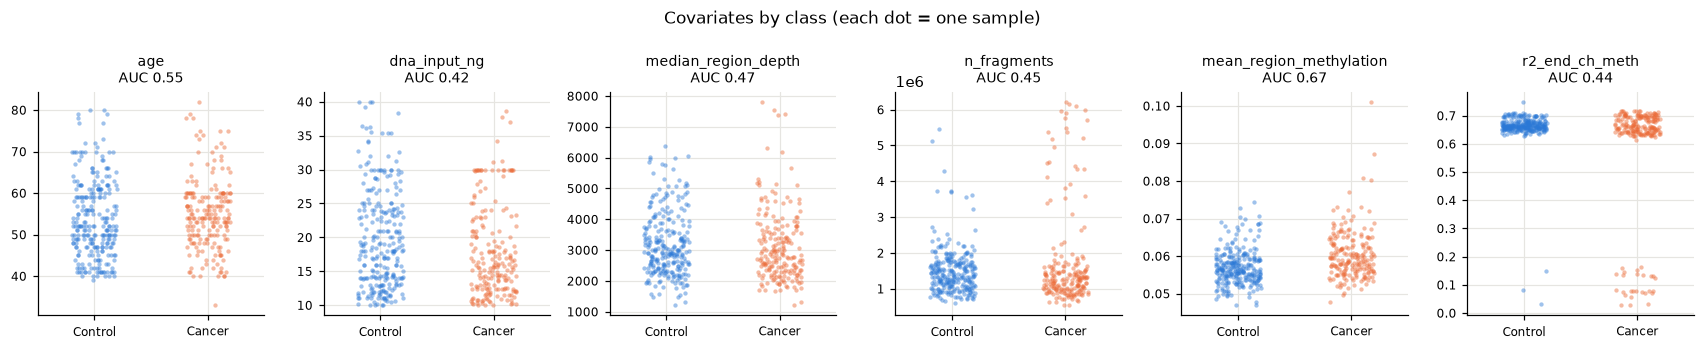

In [4]:
fig, axes = plt.subplots(1, len(numeric), figsize=(2.6 * len(numeric), 3.2))
rng = np.random.default_rng(SEED)
for ax, col in zip(axes, numeric):
    for label in (0, 1):
        v = samples.loc[y == label, col].astype(float)
        ax.scatter(label + rng.uniform(-0.2, 0.2, len(v)), v, s=8, alpha=0.45, linewidth=0, color=CLASS_COLORS[label])
    ax.set_xticks([0, 1], ["Control", "Cancer"], fontsize=8)
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(f"{col}\nAUC {covariates.loc[col, 'auc_vs_label']:.2f}", fontsize=9)
    ax.tick_params(labelsize=8)
fig.suptitle("Covariates by class (each dot = one sample)", fontsize=11)
fig.tight_layout()
plt.show()

## 2. Data quality

- `missing_%`: values masked by step 07 (too few supporting calls or fragments) after region filtering.
- `zero_%`: exact zeros. `frac_meth` is sparse by design: in healthy plasma these regions are unmethylated, so a
  methylated fragment is rare.
- `median_support`: CpG calls (`methylation`) or fragments behind each value.

In [5]:
SUPPORT = {name: v["support"] for name, v in info["read_feature_sets"].items()}


def support_matrix(count):
    # Fragment counts behind a read-level feature, written by step 05
    df = pd.read_csv(FEATURES_DIR / f"{info['cohort']}_read_{count}.tsv", sep="\t")
    return df.set_index("sample_id").drop(columns=["run_id", "ml_label"]).loc[y.index]


rows = []
for name, M in SETS.items():
    v = M.to_numpy().ravel()
    v = v[~np.isnan(v)]
    support = coverage if name == "methylation" else support_matrix(SUPPORT[name])
    rows.append({"feature_set": name, "regions_kept": M.shape[1], "missing_%": M.isna().mean().mean() * 100,
                 "zero_%": (v == 0).mean() * 100, "median": np.median(v), "p95": np.percentile(v, 95),
                 "median_support": np.nanmedian(support[M.columns].to_numpy())})
quality = pd.DataFrame(rows).set_index("feature_set")
print(f"Regions kept in X_methylation: {X.shape[1]} of {len(regions)}; "
      f"samples with > 1% missing regions: {(X.isna().mean(axis=1) > 0.01).sum()}")
quality.round(4)

Regions kept in X_methylation: 2456 of 2473; samples with > 1% missing regions: 0


,regions_kept,missing_%,zero_%,median,p95,median_support
feature_set,,,,,,
methylation,2456,0.0016,0.1663,0.0343,0.1877,2986.0
meth,2455,0.0537,2.0336,0.0297,0.1862,1139.0
frac_meth,2232,0.5272,84.0367,0.0000,0.0216,138.0
frac_meth_short,208,8.6685,95.8689,0.0000,0.0000,24.0
mhl,2252,0.5438,1.0743,0.0004,0.0197,137.0
pdr,2141,0.6163,1.5203,0.1836,0.5325,132.0
entropy,2141,0.6163,1.4911,0.1631,0.5000,132.0
frac_short,2445,0.2546,10.5333,0.0352,0.1176,160.0


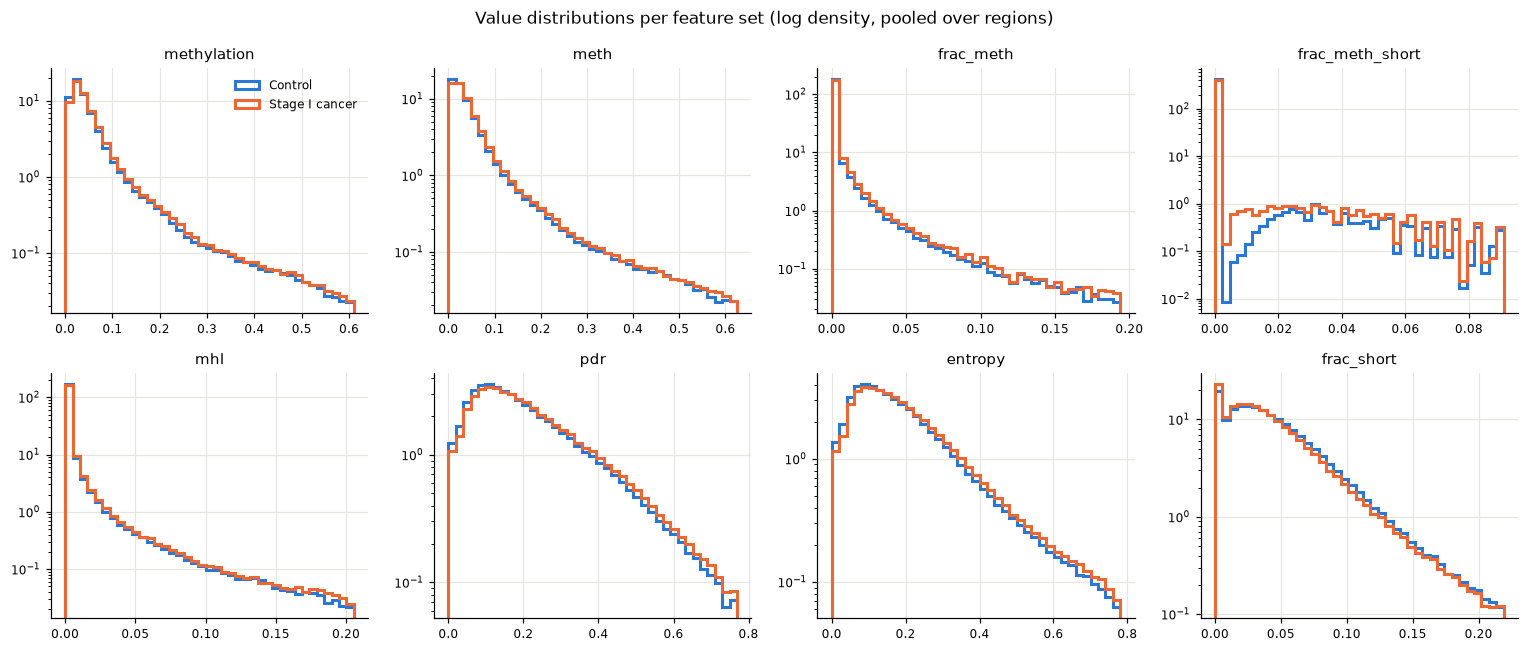

In [6]:
n = len(SETS)
fig, axes = plt.subplots(int(np.ceil(n / 4)), 4, figsize=(14, 3 * np.ceil(n / 4)))
for ax, (name, M) in zip(axes.ravel(), SETS.items()):
    values = M.to_numpy()
    bins = np.linspace(np.nanmin(values), np.nanpercentile(values, 99.5), 40)
    for label in (0, 1):
        v = values[(y == label).to_numpy()].ravel()
        ax.hist(v[~np.isnan(v)], bins=bins, density=True, histtype="step", linewidth=2,
                color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.set_title(name, fontsize=10)
    ax.set_yscale("log")
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes.ravel()[0].legend(frameon=False, fontsize=8)
fig.suptitle("Value distributions per feature set (log density, pooled over regions)", fontsize=11)
fig.tight_layout()
plt.show()

## 3. Technical confounding

A feature set that follows read depth, DNA input or a library artifact more than the label will mislead any
model. The per-sample mean of each set is correlated (Spearman) with:

- `depth`: median region depth; `fragments`: proper-pair fragments in the BAM; `dna_input`: DNA input (ng)
- `artifact`: `r2_end_ch_meth`, the methylation of the filled-in R2 end, a measure of the end-repair artifact
- `batch` and `label`, for comparison

With 460 samples even |ρ| ≈ 0.1 is nominally significant, so the size of ρ matters, not its p-value.

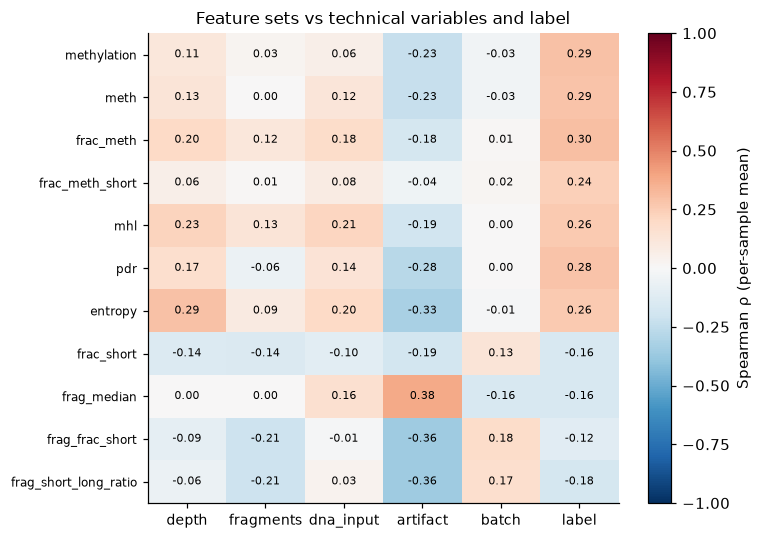

In [7]:
technical = pd.DataFrame({
    "depth": samples["median_region_depth"],
    "fragments": samples["n_fragments"],
    "dna_input": samples["dna_input_ng"],
    "artifact": samples["r2_end_ch_meth"],
    "batch": (batch == batch.value_counts().index[0]).astype(int),
    "label": y,
})
per_sample = {name: M.mean(axis=1) for name, M in SETS.items()}
per_sample.update({col: X_sample[col] for col in X_sample.columns})
confounding = pd.DataFrame({
    name: {f"rho_{col}": stats.spearmanr(values, technical[col], nan_policy="omit")[0] for col in technical}
    for name, values in per_sample.items()
}).T

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(confounding.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
ax.set_xticks(range(confounding.shape[1]), [c[4:] for c in confounding.columns], fontsize=9)
ax.set_yticks(range(len(confounding)), confounding.index, fontsize=8)
for i in range(confounding.shape[0]):
    for j in range(confounding.shape[1]):
        ax.text(j, i, f"{confounding.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman ρ (per-sample mean)")
ax.set_title("Feature sets vs technical variables and label", fontsize=11)
fig.tight_layout()
plt.show()

**The end-repair artifact in `X_methylation`.** Step 04 counts every CpG call, including the artifact calls at the
filled-in R2 end; `meth` (step 05) drops them. If the per-sample difference between the two tracks
`r2_end_ch_meth`, `X_methylation` carries a library-specific offset.

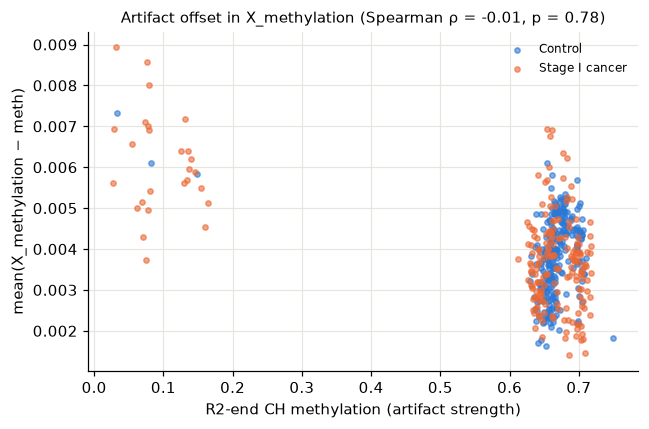

In [8]:
common = X.columns.intersection(SETS["meth"].columns)
offset = (X[common] - SETS["meth"][common]).mean(axis=1)
rho, p = stats.spearmanr(offset, samples["r2_end_ch_meth"])

fig, ax = plt.subplots(figsize=(6, 4))
for label in (0, 1):
    m = (y == label).to_numpy()
    ax.scatter(samples["r2_end_ch_meth"][m], offset[m], s=12, alpha=0.6, color=CLASS_COLORS[label], label=CLASS_NAMES[label])
ax.set_xlabel("R2-end CH methylation (artifact strength)")
ax.set_ylabel("mean(X_methylation − meth)")
ax.set_title(f"Artifact offset in X_methylation (Spearman ρ = {rho:.2f}, p = {p:.2g})", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 4. Region methylation vs label

Per region: mean methylation in each class, the difference (`delta`), the AUC of the region on its own, a
Mann-Whitney test and Benjamini-Hochberg FDR over all kept regions. Effect sizes matter more than p-values here:
ctDNA in Stage I plasma is a small fraction of the cfDNA, so even real tumour markers move the average only slightly.

In [9]:
def column_auc(M, labels):
    # AUC of every column, ignoring NaN (Mann-Whitney U / (n1 * n0))
    R = M.rank().to_numpy()
    seen = ~np.isnan(R)
    R = np.nan_to_num(R)
    pos = np.asarray(labels) == 1
    n1, n0 = seen[pos].sum(0), seen[~pos].sum(0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.Series((R[pos].sum(0) - n1 * (n1 + 1) / 2) / (n1 * n0), M.columns)


p_values = stats.mannwhitneyu(X[y == 1], X[y == 0], axis=0, nan_policy="omit").pvalue
diff = pd.DataFrame({
    "control_mean": X[y == 0].mean(),
    "cancer_mean": X[y == 1].mean(),
    "delta": X[y == 1].mean() - X[y == 0].mean(),
    "auc": column_auc(X, y),
    "p_value": np.asarray(p_values),
})
diff["fdr_bh"] = stats.false_discovery_control(diff["p_value"].fillna(1.0), method="bh")
diff = diff.join(regions[["chrom", "start0", "end"]]).sort_values("p_value")

print(f"Regions at FDR < 0.05: {(diff['fdr_bh'] < 0.05).sum()} of {len(diff)}  "
      f"(higher in cancer: {((diff['fdr_bh'] < 0.05) & (diff['delta'] > 0)).sum()}, "
      f"lower: {((diff['fdr_bh'] < 0.05) & (diff['delta'] < 0)).sum()})")
print(f"Regions with AUC ≥ 0.65 or ≤ 0.35: {((diff['auc'] - 0.5).abs() >= 0.15).sum()}")
diff.head(20).round(4)

Regions at FDR < 0.05: 1472 of 2456  (higher in cancer: 1466, lower: 6)
Regions with AUC ≥ 0.65 or ≤ 0.35: 98


,control_mean,cancer_mean,delta,auc,p_value,fdr_bh,chrom,start0,end
ELSA_2080,0.0460,0.0592,0.0132,0.7736,0.0,0.0,16,58535210,58535601
ELSA_2119,0.0650,0.0932,0.0282,0.7672,0.0,0.0,17,36666090,36666161
ELSA_1234,0.0245,0.0290,0.0046,0.7446,0.0,0.0,8,11561452,11561882
ELSA_2120,0.0451,0.0684,0.0234,0.7362,0.0,0.0,17,36666176,36666329
ELSA_0594,0.0478,0.0569,0.0091,0.7315,0.0,0.0,4,122686284,122686711
ELSA_0984,0.0379,0.0523,0.0144,0.7121,0.0,0.0,6,6002600,6002805
ELSA_1959,0.0514,0.0571,0.0057,0.7111,0.0,0.0,14,57283936,57284651
ELSA_2099,0.0806,0.1127,0.0321,0.7036,0.0,0.0,17,1960867,1960981
ELSA_1195,0.0100,0.0120,0.0020,0.6964,0.0,0.0,7,87229716,87229974
ELSA_1857,0.0184,0.0232,0.0047,0.6954,0.0,0.0,13,79170130,79170391


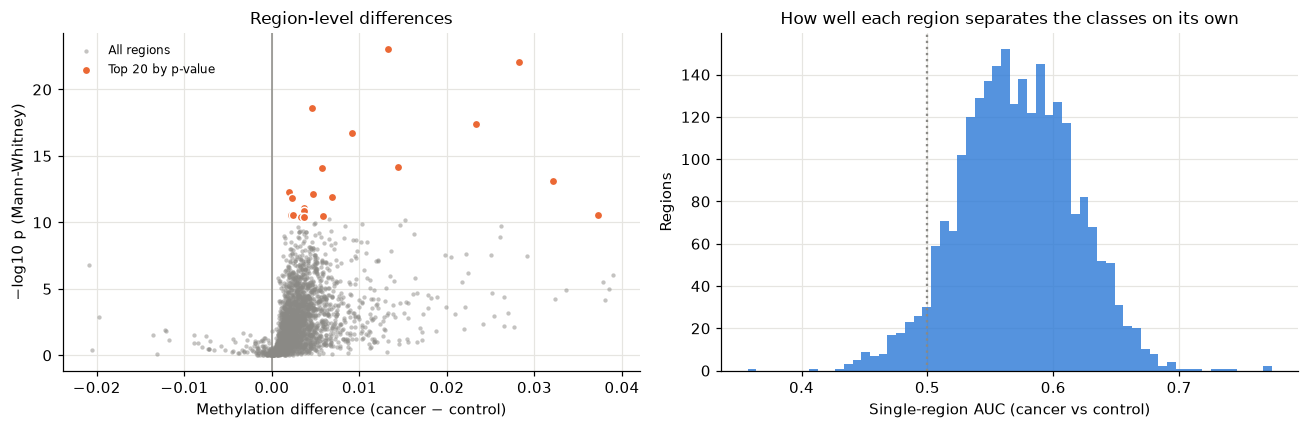

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = diff.head(20).index
ax = axes[0]
ax.scatter(diff["delta"], -np.log10(diff["p_value"]), s=8, color=MUTED, alpha=0.5, linewidth=0, label="All regions")
ax.scatter(diff.loc[top, "delta"], -np.log10(diff.loc[top, "p_value"]), s=30, color=CLASS_COLORS[1],
           edgecolor="white", linewidth=1, label="Top 20 by p-value")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Methylation difference (cancer − control)")
ax.set_ylabel("−log10 p (Mann-Whitney)")
ax.set_title("Region-level differences", fontsize=11)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.hist(diff["auc"], bins=60, color=CLASS_COLORS[0], alpha=0.8)
ax.axvline(0.5, color=MUTED, linestyle=":")
ax.set_xlabel("Single-region AUC (cancer vs control)")
ax.set_ylabel("Regions")
ax.set_title("How well each region separates the classes on its own", fontsize=11)
fig.tight_layout()
plt.show()

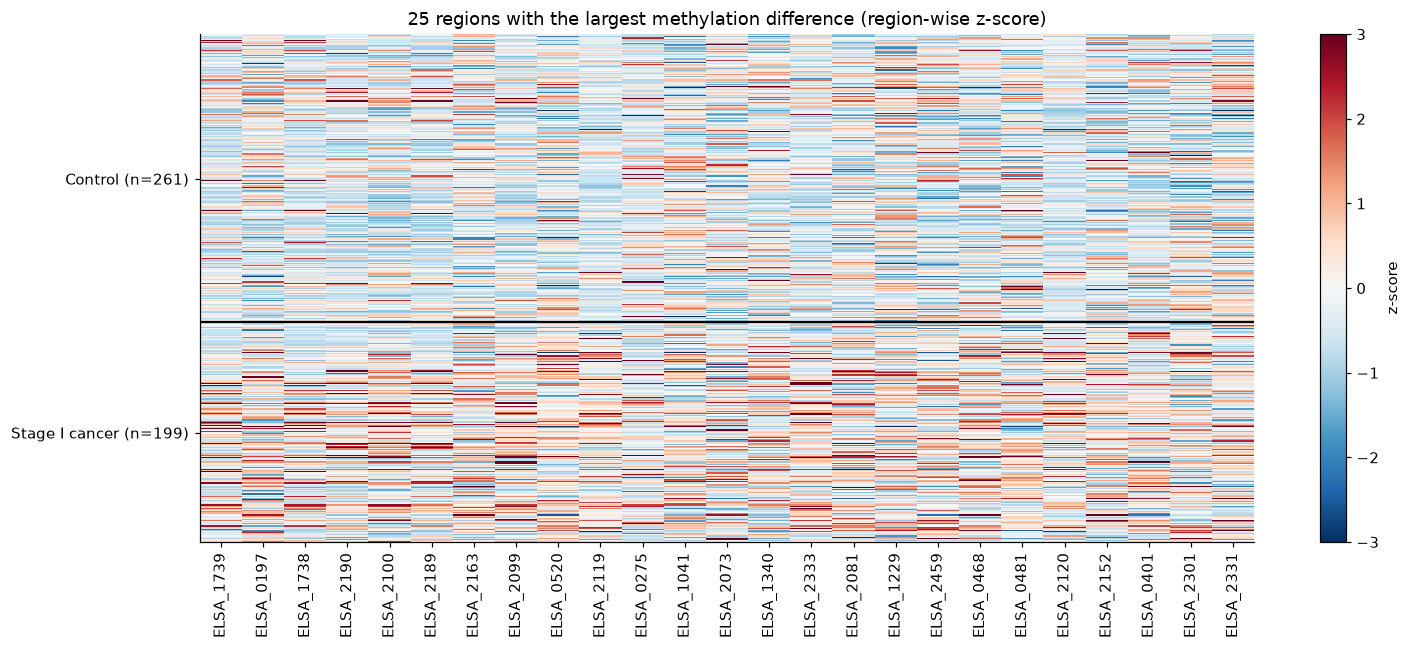

In [11]:
top25 = diff.reindex(diff["delta"].abs().sort_values(ascending=False).index).head(25).index
heat = X[top25].fillna(X[top25].median())
heat_z = ((heat - heat.mean()) / heat.std(ddof=0)).replace([np.inf, -np.inf], np.nan).fillna(0)
order = np.argsort(y.to_numpy(), kind="stable")
n_ctrl = int((y == 0).sum())

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(heat_z.to_numpy()[order], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
ax.axhline(n_ctrl - 0.5, color="black", linewidth=1.5)
ax.set_yticks([n_ctrl / 2, n_ctrl + (len(y) - n_ctrl) / 2],
              [f"Control (n={n_ctrl})", f"Stage I cancer (n={len(y) - n_ctrl})"])
ax.set_xticks(range(len(top25)), top25, rotation=90)
ax.grid(False)
ax.set_title("25 regions with the largest methylation difference (region-wise z-score)")
fig.colorbar(im, ax=ax, label="z-score")
fig.tight_layout()
plt.show()

## 5. Structure: PCA by label and by batch

If the sequencing batches separate more clearly than the labels, a model can learn the batch. For each of the
first components, the AUC against the label and against the batch shows which one it follows.

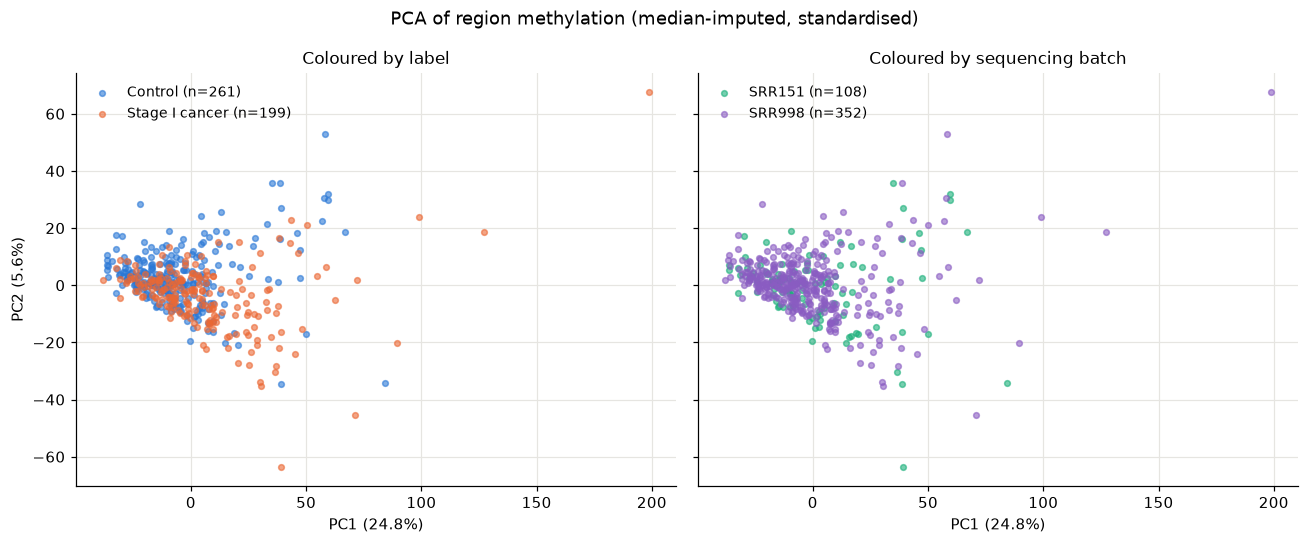

,explained_%,auc_label,auc_batch
PC1,24.836,0.655,0.523
PC2,5.592,0.685,0.519
PC3,1.983,0.524,0.505
PC4,1.740,0.626,0.598
PC5,1.300,0.596,0.567
PC6,1.002,0.671,0.649
PC7,0.968,0.545,0.538
PC8,0.875,0.529,0.573
PC9,0.691,0.532,0.530
PC10,0.621,0.643,0.561


In [12]:
Z = StandardScaler().fit_transform(X.fillna(X.median()))
pca = PCA(n_components=10, random_state=SEED).fit(Z)
pcs = pd.DataFrame(pca.transform(Z), index=X.index, columns=[f"PC{i + 1}" for i in range(10)])
batch01 = (batch == batch.value_counts().index[0]).astype(int)
pc_table = pd.DataFrame({
    "explained_%": pca.explained_variance_ratio_ * 100,
    "auc_label": [max(a, 1 - a) for a in (roc_auc_score(y, pcs[c]) for c in pcs)],
    "auc_batch": [max(a, 1 - a) for a in (roc_auc_score(batch01, pcs[c]) for c in pcs)],
}, index=pcs.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for label in (0, 1):
    m = (y == label).to_numpy()
    axes[0].scatter(pcs.loc[m, "PC1"], pcs.loc[m, "PC2"], s=14, alpha=0.6, color=CLASS_COLORS[label],
                    label=f"{CLASS_NAMES[label]} (n={m.sum()})")
for b, color in zip(sorted(batch.unique()), BATCH_COLORS):
    m = (batch == b).to_numpy()
    axes[1].scatter(pcs.loc[m, "PC1"], pcs.loc[m, "PC2"], s=14, alpha=0.6, color=color, label=f"{b} (n={m.sum()})")
for ax, title in zip(axes, ["Coloured by label", "Coloured by sequencing batch"]):
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
    ax.set_title(title, fontsize=11)
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
fig.suptitle("PCA of region methylation (median-imputed, standardised)", fontsize=12)
fig.tight_layout()
plt.show()
pc_table.round(3)

## 6. Is the region signal the same in both batches?

The per-region AUC is computed inside each batch separately. If the same regions point the same way in both,
the biology is shared and a batch shift is an offset that a model has to handle; if they disagree, the batches
carry different signal.

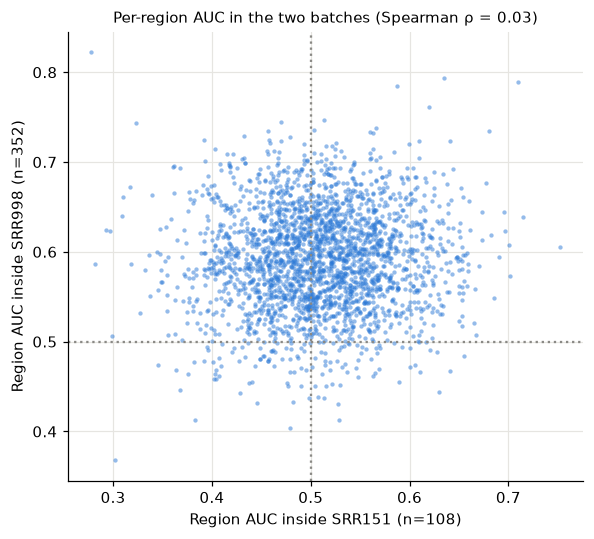

Regions with |AUC − 0.5| ≥ 0.15 in SRR151: 66; same direction in SRR998: 65%


In [13]:
by_batch = {}
for b in sorted(batch.unique()):
    m = (batch == b).to_numpy()
    by_batch[b] = column_auc(X[m], y[m])
by_batch = pd.DataFrame(by_batch)
b1, b2 = by_batch.columns
rho, _ = stats.spearmanr(by_batch[b1], by_batch[b2], nan_policy="omit")
strong = (by_batch[b1] - 0.5).abs() >= 0.15
agree = (np.sign(by_batch.loc[strong, b1] - 0.5) == np.sign(by_batch.loc[strong, b2] - 0.5)).mean()

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(by_batch[b1], by_batch[b2], s=8, alpha=0.5, color=CLASS_COLORS[0], linewidth=0)
ax.axhline(0.5, color=MUTED, linestyle=":")
ax.axvline(0.5, color=MUTED, linestyle=":")
ax.set_xlabel(f"Region AUC inside {b1} (n={(batch == b1).sum()})")
ax.set_ylabel(f"Region AUC inside {b2} (n={(batch == b2).sum()})")
ax.set_title(f"Per-region AUC in the two batches (Spearman ρ = {rho:.2f})", fontsize=10)
fig.tight_layout()
plt.show()
print(f"Regions with |AUC − 0.5| ≥ 0.15 in {b1}: {strong.sum()}; same direction in {b2}: {agree:.0%}")

## 7. Redundancy between feature sets

For each pair of feature sets, the Spearman correlation across samples is computed region by region; the matrix
shows its median over shared regions. A set that correlates ~1 with `methylation` adds little; a low correlation
means new information or noise, which section 8 tells apart.

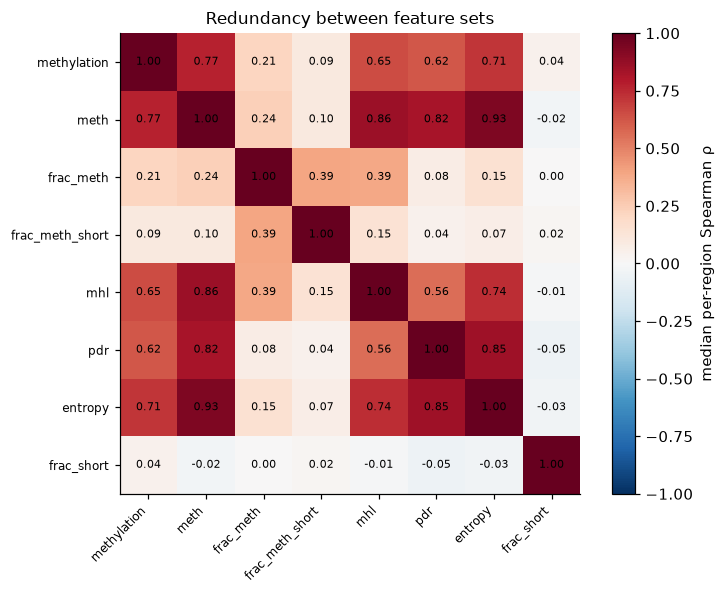

In [14]:
def median_region_correlation(A, B):
    shared = A.columns.intersection(B.columns)
    if len(shared) == 0:
        return np.nan
    return float(np.nanmedian(A[shared].rank().corrwith(B[shared].rank())))


names = list(SETS)
redundancy = pd.DataFrame([[median_region_correlation(SETS[a], SETS[b]) for b in names] for a in names],
                          index=names, columns=names)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(redundancy.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{redundancy.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, label="median per-region Spearman ρ")
ax.set_title("Redundancy between feature sets", fontsize=11)
fig.tight_layout()
plt.show()

## 8. Univariate signal against a permutation null

A feature is **strong** if its AUC is at least 0.15 away from 0.5. The number of strong features with the real
labels is compared with the number under 1,000 random labellings; the p-value is the share of labellings with at
least as many strong features (the true labelling included).

In [15]:
STRONG = 0.15
N_RANDOM = 1000
rng = np.random.default_rng(SEED)
true_labels = y.to_numpy().astype(bool)
labelings = np.vstack([true_labels, [rng.permutation(true_labels) for _ in range(N_RANDOM)]])


def auc_matrix(M, labelings):
    # AUC of every column (columns) for every labelling (rows), ignoring NaN
    ranks = M.rank().to_numpy()
    seen = ~np.isnan(ranks)
    ranks = np.nan_to_num(ranks)
    pos = labelings.astype(float)
    n_pos, n_neg = pos @ seen, (1 - pos) @ seen
    with np.errstate(invalid="ignore", divide="ignore"):
        return (pos @ ranks - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


rows, feature_auc = [], {}
for name, M in {**SETS, "sample (fragment length)": X_sample}.items():
    auc = auc_matrix(M, labelings)
    strong = (np.abs(auc - 0.5) >= STRONG).sum(axis=1)
    feature_auc[name] = pd.Series(auc[0], index=M.columns)
    rows.append({"feature_set": name, "n_features": M.shape[1], "strong_observed": int(strong[0]),
                 "strong_null_mean": strong[1:].mean(), "strong_null_p95": np.percentile(strong[1:], 95),
                 "max_abs_auc_shift": np.nanmax(np.abs(auc[0] - 0.5)), "signal_p": (strong >= strong[0]).mean()})
signal = pd.DataFrame(rows).set_index("feature_set")
signal.round(3)

,n_features,strong_observed,strong_null_mean,strong_null_p95,max_abs_auc_shift,signal_p
feature_set,,,,,,
methylation,2456,98,0.0,0.0,0.274,0.001
meth,2455,27,0.0,0.0,0.244,0.001
frac_meth,2232,3,0.0,0.0,0.230,0.001
frac_meth_short,208,0,0.0,0.0,0.111,1.000
mhl,2252,9,0.0,0.0,0.199,0.001
pdr,2141,6,0.0,0.0,0.218,0.001
entropy,2141,21,0.0,0.0,0.246,0.001
frac_short,2445,3,0.0,0.0,0.156,0.001
sample (fragment length),3,0,0.0,0.0,0.103,1.000


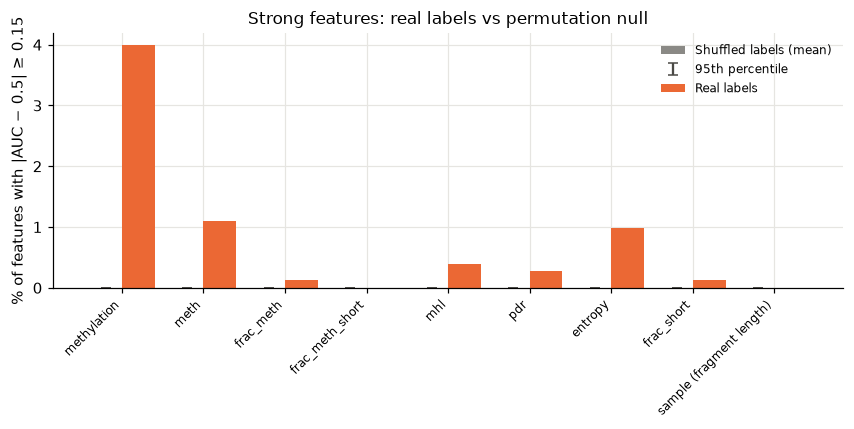

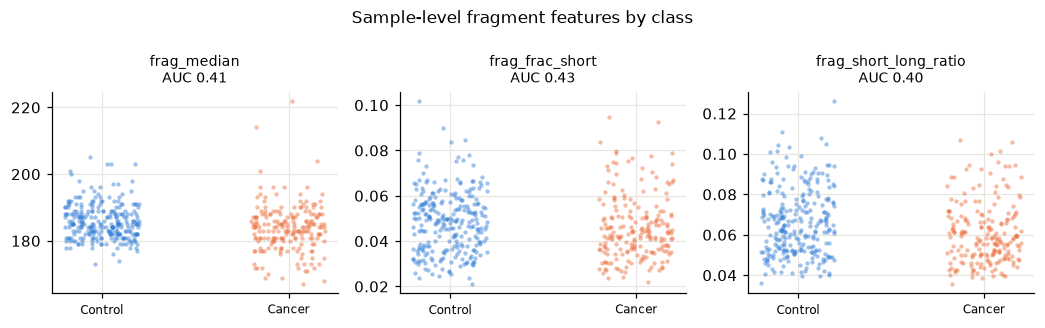

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(signal))
obs = signal["strong_observed"] / signal["n_features"] * 100
null = signal["strong_null_mean"] / signal["n_features"] * 100
p95 = signal["strong_null_p95"] / signal["n_features"] * 100
ax.bar(x - 0.2, null, width=0.4, color=MUTED, label="Shuffled labels (mean)")
ax.errorbar(x - 0.2, null, yerr=[np.zeros(len(x)), p95 - null], fmt="none", ecolor="#4a4945", capsize=3,
            label="95th percentile")
ax.bar(x + 0.2, obs, width=0.4, color=CLASS_COLORS[1], label="Real labels")
ax.set_xticks(x, signal.index, rotation=45, ha="right", fontsize=8)
ax.set_ylabel(f"% of features with |AUC − 0.5| ≥ {STRONG}")
ax.set_title("Strong features: real labels vs permutation null", fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, X_sample.shape[1], figsize=(3.2 * X_sample.shape[1], 3))
for ax, col in zip(np.atleast_1d(axes), X_sample.columns):
    for label in (0, 1):
        v = X_sample.loc[y == label, col]
        ax.scatter(label + rng.uniform(-0.2, 0.2, len(v)), v, s=8, alpha=0.45, linewidth=0, color=CLASS_COLORS[label])
    ax.set_xticks([0, 1], ["Control", "Cancer"], fontsize=8)
    ax.set_title(f"{col}\nAUC {feature_auc['sample (fragment length)'][col]:.2f}", fontsize=9)
fig.suptitle("Sample-level fragment features by class", fontsize=11)
fig.tight_layout()
plt.show()

## 9. Summary

One row per feature set. A useful set has enough support (`missing_%` low), weak correlation with the technical
variables, more strong features than the permutation null (`signal_p` small) and, to add something new, a low
correlation with `methylation`. The tables are written to `results/data_analysis/`.

In [17]:
summary = (
    quality[["regions_kept", "missing_%", "zero_%", "median_support"]]
    .join(confounding[["rho_depth", "rho_artifact", "rho_batch", "rho_label"]], how="outer")
    .join(redundancy["methylation"].rename("rho_vs_methylation"), how="left")
    .join(signal[["strong_observed", "strong_null_mean", "signal_p"]], how="outer")
)
summary = summary.loc[[i for i in [*SETS, "sample (fragment length)", *X_sample.columns] if i in summary.index]]

covariates.to_csv(OUT_DIR / "covariates.tsv", sep="\t")
quality.to_csv(OUT_DIR / "quality.tsv", sep="\t")
confounding.to_csv(OUT_DIR / "confounding.tsv", sep="\t")
diff.to_csv(OUT_DIR / "region_differences.tsv", sep="\t")
pc_table.to_csv(OUT_DIR / "pca.tsv", sep="\t")
by_batch.to_csv(OUT_DIR / "region_auc_by_batch.tsv", sep="\t")
redundancy.to_csv(OUT_DIR / "redundancy.tsv", sep="\t")
signal.to_csv(OUT_DIR / "univariate_signal.tsv", sep="\t")
summary.to_csv(OUT_DIR / "feature_set_summary.tsv", sep="\t")
summary.round(3)

,regions_kept,missing_%,zero_%,median_support,rho_depth,rho_artifact,rho_batch,rho_label,rho_vs_methylation,strong_observed,strong_null_mean,signal_p
feature_set,,,,,,,,,,,,
methylation,2456.0,0.002,0.166,2986.0,0.109,-0.234,-0.032,0.294,1.000,98.0,0.0,0.001
meth,2455.0,0.054,2.034,1139.0,0.130,-0.227,-0.031,0.287,0.771,27.0,0.0,0.001
frac_meth,2232.0,0.527,84.037,138.0,0.200,-0.178,0.014,0.305,0.212,3.0,0.0,0.001
frac_meth_short,208.0,8.668,95.869,24.0,0.062,-0.045,0.018,0.238,0.094,0.0,0.0,1.000
mhl,2252.0,0.544,1.074,137.0,0.226,-0.188,0.001,0.261,0.654,9.0,0.0,0.001
pdr,2141.0,0.616,1.520,132.0,0.165,-0.279,0.001,0.285,0.620,6.0,0.0,0.001
entropy,2141.0,0.616,1.491,132.0,0.289,-0.327,-0.010,0.260,0.712,21.0,0.0,0.001
frac_short,2445.0,0.255,10.533,160.0,-0.140,-0.186,0.129,-0.160,0.042,3.0,0.0,0.001
sample (fragment length),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.000
